In [1]:
# 1. Import Library

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

In [2]:
#2 Load the iris dataset

iris = load_iris()

X = iris.data # Features
y = iris.target #target

print("Feature names:" , iris.feature_names)
print("Target names:" , iris.target_names)

Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: ['setosa' 'versicolor' 'virginica']


In [5]:
# 3. Split the dataset

X_train, X_test, y_train, y_test = train_test_split (X, y , test_size=0.2, random_state = 42)

print("Training samples:" , X_train.shape[0])
print("Testing samples:" , X_test.shape[0])

Training samples: 120
Testing samples: 30


In [7]:
#4 Train knn classifier

k= 3 #number of neighbors
knn= KNeighborsClassifier(n_neighbors=k)

knn.fit(X_train , y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [9]:
# 5. Evaluate the model

y_pred = knn.predict(X_test)

print("Accuracy:" ,  accuracy_score(y_test , y_pred))
print("\nClassification Report:\n" , classification_report(y_test , y_pred))

Accuracy: 1.0

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [10]:
# 6. Test with unknown data

# example unknown data ( sepal length, sepal width, petal length, petal width)
unknown_sample= np.array([[5.1, 3.5, 1.4, 0.2]])

prediction = knn.predict(unknown_sample)
predicted_class = iris.target_names[prediction[0]]

print("Predicted class for unknown sample:" , predicted_class)

Predicted class for unknown sample: setosa


In [11]:
# 7. Try mutiple unknown samples

unknown_samples= np.array([
    [6.7, 3.1, 4.7, 1.5], # likely versicolor
    [7.2, 3.6, 6.1, 2.5], # likely virginica
    [5.0, 3.4, 1.5, 0.2] # liekly setosa
])

predictions = knn.predict(unknown_samples)

for i, pred in enumerate(predictions):
    print(f"Sample {i+1} predicted as:" , iris.target_names[pred])
    

Sample 1 predicted as: versicolor
Sample 2 predicted as: virginica
Sample 3 predicted as: setosa


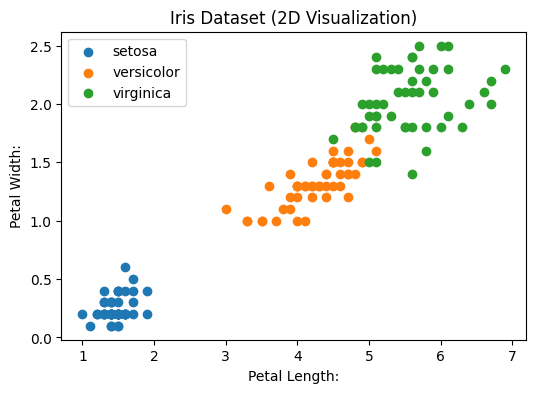

In [12]:
# 8. Visualize the dataset (2D)

#use only 2 feature: petal length (2) and petal width (3)
X_vis= X[:, 2:4]
y_vis= y

plt.figure(figsize=(6, 4))
for i, target_name in enumerate(iris.target_names):
    plt.scatter(
        X_vis[y_vis == i, 0],
        X_vis[y_vis == i, 1],
        label= target_name
    )

plt.xlabel("Petal Length:")
plt.ylabel("Petal Width:")
plt.legend()
plt.title("Iris Dataset (2D Visualization)")
plt.show()


In [14]:
# 9. train KNN on 2D data

X_train_vis, X_test_vis, y_train_vis, y_test_vis = train_test_split(
    X_vis, y_vis, test_size = 0.2, random_state=42
)

knn_vis = KNeighborsClassifier(n_neighbors=3)
knn_vis.fit(X_train_vis, y_train_vis)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


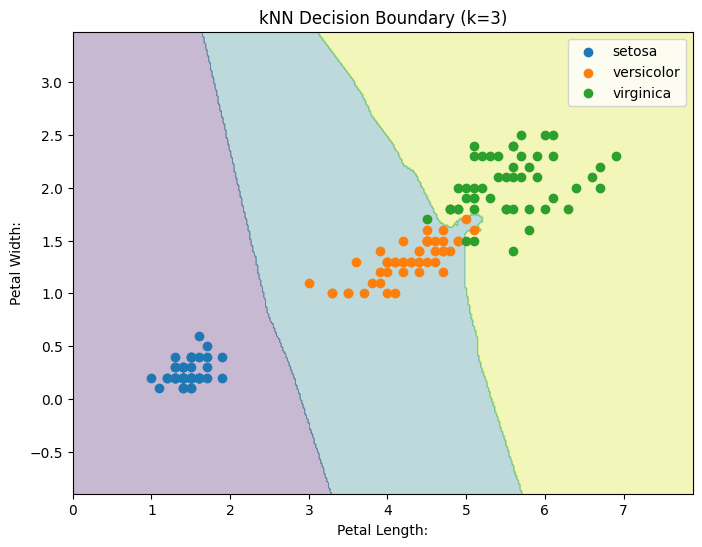

In [16]:
# 10. Plot decision Boundary

#create mesh grid
h= 0.02 # step size
x_min , x_max =X_vis[:, 0].min() -1, X_vis[:, 0].max() +1
y_min , y_max =X_vis[:, 1].min() -1, X_vis[:, 1].max() +1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, h),
    np.arange(y_min, y_max, h)
)

#Predict over grid
Z = knn_vis.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

#Plot decision boundary
plt.figure(figsize=(8, 6))
plt.contourf(xx , yy , Z , alpha=0.3)

#Plot actual points
for i, target_name in enumerate(iris.target_names):
    plt.scatter(
        X_vis[y_vis == i,0],
        X_vis[y_vis == i,1],
        label = target_name
    )

plt.xlabel("Petal Length:")
plt.ylabel("Petal Width:")
plt.legend()
plt.title("kNN Decision Boundary (k=3)")
plt.show()

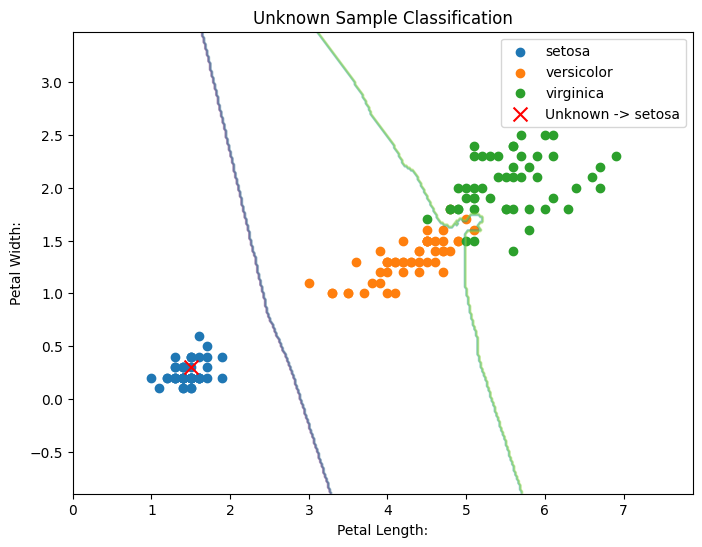

Predicted class: setosa


In [18]:
# 11. Visualise unknown smample classification

# unknown sample( 2 feature: petal length and petal width )
unknown = np.array([[1.5, 0.3]])

pred = knn_vis.predict(unknown)
label =iris.target_names[pred[0]]

plt.figure(figsize=(8, 6))
plt.contour(xx, yy, Z, alpha=0.3)

for i, target_name in enumerate(iris.target_names):
    plt.scatter(
        X_vis[y_vis == i, 0],
        X_vis[y_vis == i, 1],
        label= target_name
    )

plt.scatter(unknown[:,0], unknown[:,1], color='red' , marker ='x' , s=100, label=f"Unknown -> {label}")

plt.xlabel("Petal Length:")
plt.ylabel("Petal Width:")
plt.legend()
plt.title("Unknown Sample Classification")
plt.show()

print("Predicted class:",label)